<a href="https://colab.research.google.com/github/scottaudrey/svd-food-recommendation-system/blob/main/notebooks/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part A: Load your project functions and data**

In [11]:
import os
import subprocess
import sys

USER = "scottaudrey"
REPO = "svd-food-recommendation-system"

if os.path.exists(REPO):
  subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
  subprocess.run(
    ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
    check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

This code connects to my GitHub repository and imports the reusable functions from Milestone 2. These functions will be used to split the ratings, create the rating matrix, calculate RMSE, and build the baseline model.

In [12]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://github.com/ryannewhouse11/FoodReviewData/releases/latest/download/recipereview.zip"
urllib.request.urlretrieve(url, "/content/recipereview.zip")

if not os.path.exists("/content/recipereview.zip"):
  urllib.request.urlretrieve(url, "/content/recipereview.zip")


with zipfile.ZipFile("/content/recipereview.zip", "r") as z:
  csv_files = [
      name for name in z.namelist()
      if name.lower().endswith(".csv") and not name.startswith("_MACOSX/")
  ]

  with z.open(csv_files[0]) as f:
    ratings = pd.read_csv(
        f,
        sep=",",
        header=0,
        names=["num_records", "recipe_number", "recipe_code", "recipe_name",
               "comment_id", "user_id", "user_name", "user_reputation", "created_at",
               "reply_count", "thumbs_up", "thumbs_down", "stars", "best_score", "text"]
    )

# This part is added to factor data and make these ID into consecutive integers
# This will help with Part B
# Code from chatgpt
ratings["user_id"] = pd.factorize(ratings["user_id"])[0] + 1
ratings["recipe_code"] = pd.factorize(ratings["recipe_code"])[0] + 1

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

fit: 16983 validation: 560 test: 639


This code downloads the food review dataset and loads the ratings into a DataFrame. It removes missing values and converts user IDs and recipe codes into consecutive numbers. The data is then divided into fitting, validation, and testing sets. The fitting set is used to build the model, the validation set is used to compare models, and the testing set is saved for the final evaluation.

# **Part B: Set up a fair validation comparison**

In [13]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)

val_truth = val["stars"].to_numpy()
val_u = val["user_id"].to_numpy() - 1
val_i = val["recipe_code"].to_numpy() - 1

def score_at(P, rows, cols, truth):
  """RMSE for selected entries of a prediction matrix."""
  pred = np.clip(P[rows, cols], 1, 5)
  return rmse(pred, truth)

This code creates a user-by-recipe rating matrix using only the fitting data. Missing ratings are represented by NaN. The validation ratings are kept separate to test how accurately the model predicts unknown ratings. The score_at function calculates RMSE by comparing predicted ratings to actual ratings. A lower RMSE means the predictions are more accurate.

# **Part C: Build the baseline prediction matrix**

In [14]:
def baseline_matrix(R):
  """Full matrix: overall mean plus user and recipe effects."""
  mu, b_user, b_item = bias_baseline(R)
  return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: nan


/content/svd-food-recommendation-system/src/models.py:9: RuntimeWarning: Mean of empty slice
  b_user = np.nanmean(R - mu, axis=1)


This code creates a baseline prediction matrix using the overall average rating, user rating differences, and recipe rating differences. It then calculates the validation RMSE to measure how accurately the baseline predicts ratings. This gives us a starting point to compare with the SVD models.

# **Part D: Create a rank-k helper**

In [15]:
def rank_k(U, s, Vt, k):
  """Build a rank-k matrix from an already computed SVD."""
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

This code creates a function that uses the first k singular values and their corresponding vectors to reconstruct a lower-rank approximation of the rating matrix. Using a smaller rank helps simplify the matrix while keeping the most important patterns in the ratings.

# **Part E: Model 1 — fill gaps with recipe averages**

In [16]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

This code fills missing ratings with the average rating for each recipe while keeping the known ratings unchanged. It then applies SVD to the completed matrix. This allows the model to estimate missing ratings using patterns in the user-recipe rating data.

# **Part F: Model 2 — let SVD explain what the baseline misses**

In [17]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

This code calculates the difference between known ratings and the baseline predictions. Missing differences are filled with zero, and SVD is applied to the resulting matrix. The goal is to find patterns that the baseline model did not already explain.

# **Part G: Choose rank using validation RMSE**

In [18]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
  P1 = rank_k(U1, s1, Vt1, k)
  P2 = rank_k(U2, s2, Vt2, k) + B_fit
  val_err1.append(score_at(P1, val_u, val_i, val_truth))
  val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:", best_k1, "  Validation RMSE:", min(val_err1))
print("Best Model 2 k:", best_k2, " Validation RMSE:", min(val_err2))

Best Model 1 k: 1   Validation RMSE: 1.4348967110661779
Best Model 2 k: 1  Validation RMSE: nan


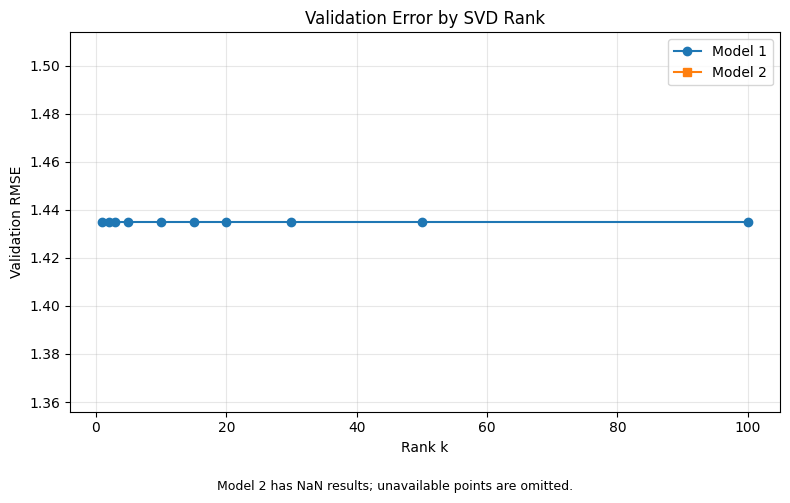

In [24]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(8, 5))
plt.plot(ks, val_err1, "o-", label="Model 1")
plt.plot(ks, val_err2, "s-", label="Model 2")

if np.isfinite(baseline_val_rmse):
  plt.axhline(baseline_val_rmse, color="gray",
              linestyle="--", label="Baseline")

plt.xlabel("Rank k")
plt.ylabel("Validation RMSE")
plt.title("Validation Error by SVD Rank")
plt.legend()
plt.grid(alpha=0.3)

if not np.all(np.isfinite(val_err2)):
  plt.figtext(0.5, 0.01,
              "Model 2 has NaN results; unavailable points are omitted.",
              ha="center", fontsize=9)

plt.tight_layout(rect=(0, 0.05, 1, 1))
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/validation_rmse.png", dpi=200)
plt.show()

This code tests different rank values for Models 1 and 2 and calculates their validation RMSE. It selects the rank with the lowest error for each model and creates a graph comparing their performance with the baseline. A lower RMSE means the model makes more accurate predictions.

# **Part H: Model 3 — iteratively improve the missing-value guesses**

In [19]:
def iterative_svd_predict(R, k, n_iter=10):
  """Predict ratings by repeatedly"""
  known = ~np.isnan(R)
  B = baseline_matrix(R)
  X = np.where(known, R - B, 0.0)

  for _ in range(n_iter):
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    L = rank_k(U, s, Vt, k)
    X = np.where(known, R - B, L)

  return L + B

In [20]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
  P3 = iterative_svd_predict(R_fit, k, n_iter=10)
  val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: nan


This code creates an iterative SVD model that repeatedly updates the estimates for missing ratings while keeping the known rating differences unchanged. It tests several ranks and compares their validation RMSE values to determine which rank produces the most accurate predictions.

# **Part I: Refit and evalute on the test set once**

In [21]:
R_train = to_matrix(train)
test_truth = test["stars"].to_numpy()
test_u = test["user_id"].to_numpy() - 1
test_i = test["recipe_code"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
  test_prediction = iterative_svd_predict(
    R_train, best_k3, n_iter=10)
  chosen_model = """iterative SVD"""
elif min(val_err2) < min(val_err1):
  known_train = ~np.isnan(R_train)
  X_train = np.where(known_train, R_train - B_train, 0.0)
  U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
  test_prediction = rank_k(U, s, Vt, best_k2) + B_train
  """chosen_model = baseline plus low-rank deviations"""
else:
  known_train = ~np.isnan(R_train)
  mu_train = np.nanmean(R_train)
  n_item_train = known_train.sum(axis=0)
  means_train = np.full(R_train.shape[1], mu_train)
  has_train = n_item_train > 0
  means_train[has_train] = (
    np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
  F_train = np.where(known_train, R_train, means_train[None, :])
  U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
  test_prediction = rank_k(U, s, Vt, best_k1)
  chosen_model = """SVD of recipe-reveiw-average-filled matrix"""

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

/content/svd-food-recommendation-system/src/models.py:9: RuntimeWarning: Mean of empty slice
  b_user = np.nanmean(R - mu, axis=1)


Chosen model: SVD of recipe-reveiw-average-filled matrix
Baseline test RMSE: nan
Chosen model test RMSE: 1.2603


This code selects the SVD model with the lowest validation RMSE and rebuilds it using the full training dataset. It then evaluates the model using the test ratings that were kept separate during training. The test RMSE measures how accurately the chosen model predicts ratings it has not seen before.

# **Part J: Make a few recommendations**

In [22]:
item_info = ratings[
    ["recipe_code", "recipe_name"]
].drop_duplicates(subset=["recipe_code"])
item_info.columns = ["recipe_code", "recipe_name"]

user_id = 1
user_row = user_id - 1

unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
  title = item_info.loc[item_info["recipe_code"] == col + 1, "recipe_name"].iloc[0]

  print(title, "predicted rating:", round(predicted_scores[col], 2))

Grilled Huli Huli Chicken predicted rating: 5.0
Fluffy Pancakes predicted rating: 5.0
Creamy White Chili predicted rating: 5.0
Best Ever Banana Bread predicted rating: 5.0
Brown Sugar Oatmeal Pancakes predicted rating: 5.0


In [23]:
# NOTE: this shows the rating distribution for the file
# The reason all 5 recipes have a 5.0 rating is because there is a
# high amount of 5 star ratings in this data set
print("Rating distribution:")
print(ratings["stars"].value_counts().sort_index())

print("\nAverage rating:")
print(ratings["stars"].mean())

print("\nKnown training ratings:")
print(np.sum(~np.isnan(R_train)))

print("\nTotal matrix entries:")
print(R_train.size)

Rating distribution:
stars
0     1696
1      280
2      232
3      490
4     1655
5    13829
Name: count, dtype: int64

Average rating:
4.28880211197888

Known training ratings:
1

Total matrix entries:
1381200


This code uses the chosen SVD model to recommend five recipes that a selected user has not rated in the training data. It identifies the recipes with the highest predicted ratings and displays their names and scores. These predictions estimate how much the user might like each recipe, but they do not guarantee that the user will enjoy them.